# Gaze in regions of interest around events

Where do participants look after a stimulus appears, and does it relate to
what they choose? This tutorial cuts the gaze data into segments around
events and analyses them with regions of interest (ROIs):

1. define ROIs on the screen
2. cut the data around the events into segments (`get_segments()`)
3. mark where the gaze is in an ROI (`seg.gaze.roi_hits()`) and plot the
   share of trials in each ROI over time (`seg.gaze.plot_roi()`)
4. measures per trial: dwell time and first entry (`seg.gaze.dwell_time()`,
   `seg.gaze.first_entry()`)
5. combine gaze and pupil in the same trials, and average across
   participants

See [Events, intervals and segments](../user_guide/events_intervals.rst) and
[Regions of interest](../user_guide/rois.rst) in the user guide for an
overview.

In [1]:
import pypillometry as pp
from pypillometry import u
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pp.logging_set_level("WARNING")

## The data

The example dataset `rlmw_002` is a 20-minute reinforcement learning task
(downloaded on first use). In each of its 300 trials, two options were shown
to the left and right of the screen center; the participant chose one and
received a reward. The events code this in their labels:

- `S_<trial>_<left option>_<right option>`: stimulus onset
- `C_<trial>_<chosen option>_<side>`: choice (side 1 = left, 2 = right)
- `R_<trial>_<reward>`: reward

We detect and interpolate the blinks, mask the gaze during blinks (blinks
are detected on the pupil only) and outside the screen:

In [2]:
d = pp.get_example_data("rlmw_002")
d = d | pp.pupil.blinks_detect() | pp.pupil.blinks_interpolate()

bl = d.get_blinks(variables="pupil")
d.mask_intervals({"left_x": bl["left_pupil"], "left_y": bl["left_pupil"],
                  "right_x": bl["right_pupil"], "right_y": bl["right_pupil"]})
d.gaze.mask_offscreen()
list(d.events.labels[:8])

[np.str_('F_1'),
 np.str_('S_1_1_5'),
 np.str_('C_1_5_2'),
 np.str_('R_1_15'),
 np.str_('F_2'),
 np.str_('S_2_6_2'),
 np.str_('C_2_6_1'),
 np.str_('R_2_20')]

The parts of the labels become metadata of the events (see the
[event metadata tutorial](event_metadata.ipynb)); `fill_meta()` copies the
choice to all events of a trial, so that the stimuli know which side was
chosen:

In [3]:
ev = d.events.parse_labels(r"^[FSCR]_(?P<trial>\d+)")
ev = ev.parse_labels(r"^C_\d+_(?P<chosen>\d+)_(?P<side>\d+)")
ev = ev.parse_labels(r"^R_\d+_(?P<reward>\d+)")
ev = ev.fill_meta(["chosen", "side", "reward"])
d.set_events(ev)
d.events.filter("S_")[:3]

,Onset (ms),Label,trial,chosen,side,reward
0,5677.0,S_1_1_5,1.0,5.0,2.0,15.0
1,9575.0,S_2_6_2,2.0,6.0,1.0,20.0
2,12574.0,S_3_2_1,3.0,2.0,1.0,18.0


## Regions of interest

The options were shown 8° to the left and right of the screen center. A
heatmap of the gaze shows them as two clusters next to the central
fixation point. We mark each with a circle of 3° radius
(`CircularROI.from_degrees()` converts degrees to pixels with the
experimental setup of the data):

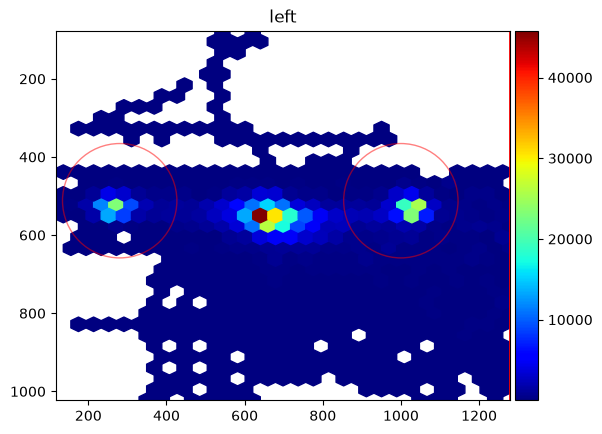

In [4]:
setup = d.experimental_setup
left_roi = pp.CircularROI.from_degrees(("-8 deg", "0 deg"), "3 deg", setup=setup, name="leftopt")
right_roi = pp.CircularROI.from_degrees(("8 deg", "0 deg"), "3 deg", setup=setup, name="rightopt")
d.plot.plot_heatmap(eyes="left", rois=[left_roi, right_roi]);

## Segments around the stimuli

`get_epochs()` defines a window around each stimulus, and `get_segments()`
cuts all channels (pupil and gaze of both eyes) in these windows. The
segments of all channels share the epochs, with the metadata of the events:

SegmentedEyeData(stimulus): 300 segments x 1750 time points (-500 to 2998 ms, 500 Hz)
  channels: left_x (7.0% missing), left_y (7.0% missing), left_pupil (0.0% missing), right_x (5.2% missing), right_y (5.2% missing), right_pupil (0.0% missing)
  epochs: Epochs 'S_' | 300 epochs, window (-500, 3000) ms
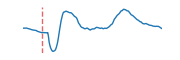
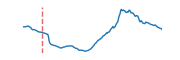
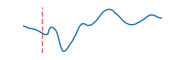
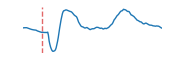
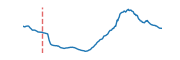
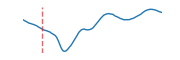

In [5]:
epochs = d.get_epochs("S_", (-500, 3000) * u.ms)
seg = d.get_segments(epochs, name="stimulus")
seg

## Where is the gaze over time?

`seg.gaze.roi_hits()` adds a channel per eye, named after the ROI
(`left_leftopt`), that is 1 where the gaze is in
the ROI and 0 outside (masked where the gaze is masked). Its mean over the
trials at each time point is the share of trials in which the participant
looked at the ROI, a *fixation curve*:

In [6]:
seg.gaze.roi_hits(left_roi)
seg.gaze.roi_hits(right_roi)
seg.channels

['left_x',
 'left_y',
 'left_pupil',
 'right_x',
 'right_y',
 'right_pupil',
 'left_leftopt',
 'right_leftopt',
 'left_rightopt',
 'right_rightopt']

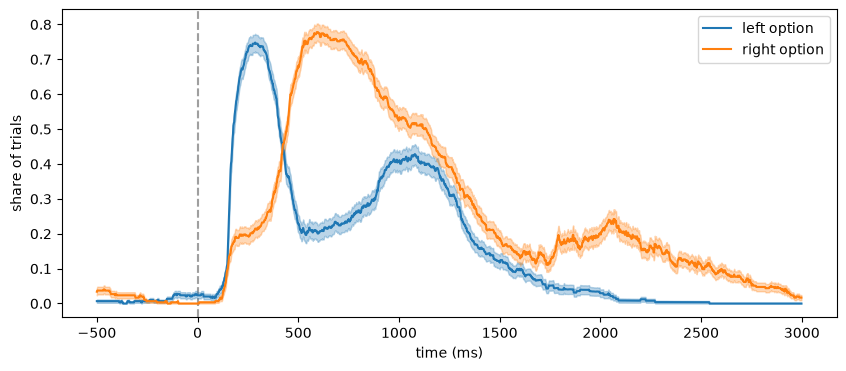

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
seg.gaze.plot_roi("leftopt", eyes="left", ax=ax, label="left option")
seg.gaze.plot_roi("rightopt", eyes="left", ax=ax, label="right option", show_legend=True)
ax.set_ylabel("share of trials");

The participant first looks at the left option (about 200 ms after the
onset), then at the right one (about 600 ms), before choosing after about
one second.

The ROI channels are masked arrays like all channels, so other curves can
be computed from them. Here, we combine them into the share of trials in
which the participant looked at the option that was *chosen* in this trial,
and at the other one. `np.ma.where` keeps the masks (`np.where` would drop
them):

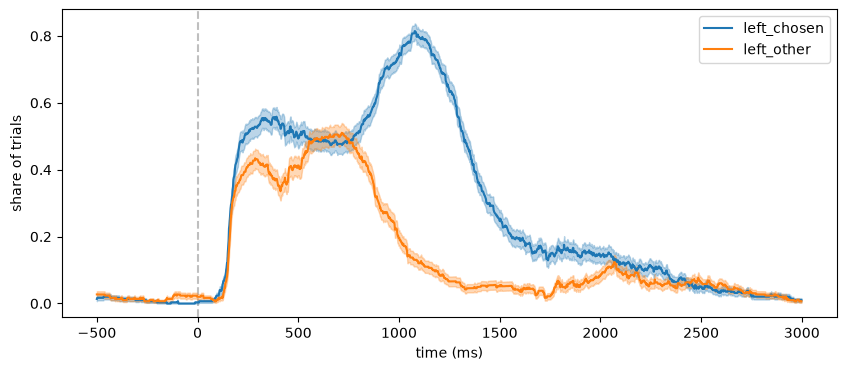

In [8]:
seg = seg.filter(side=[1, 2])   # trials with a choice
chose_left = seg.epochs.meta["side"] == 1
seg["left_chosen"] = np.ma.where(chose_left, seg["left_leftopt"], seg["left_rightopt"])
seg["left_other"] = np.ma.where(chose_left, seg["left_rightopt"], seg["left_leftopt"])

fig, ax = plt.subplots(figsize=(10, 4))
seg.plot(["left_chosen", "left_other"], ax=ax, show_legend=True)
ax.set_ylabel("share of trials");

Locked to the choice instead of the stimulus, the gaze moves to the option
that is then chosen (the *gaze cascade*):

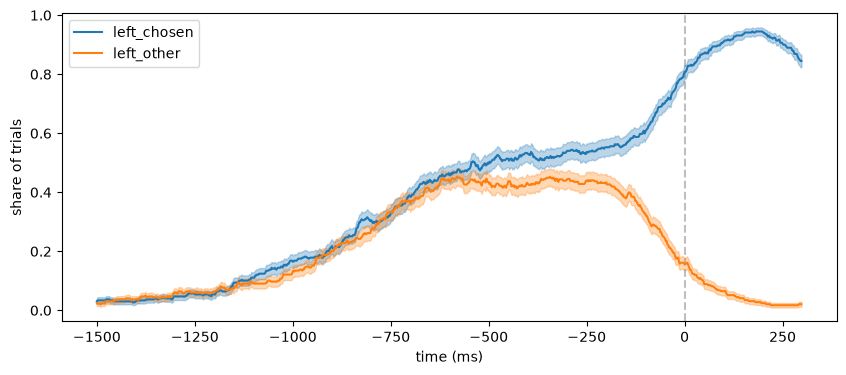

In [9]:
choice = d.get_segments(d.get_epochs("C_", (-1500, 300) * u.ms), eyes="left",
                        name="choice").filter(side=[1, 2])
choice.gaze.roi_hits(left_roi)
choice.gaze.roi_hits(right_roi)
chose_left = choice.epochs.meta["side"] == 1
choice["left_chosen"] = np.ma.where(chose_left, choice["left_leftopt"], choice["left_rightopt"])
choice["left_other"] = np.ma.where(chose_left, choice["left_rightopt"], choice["left_leftopt"])

fig, ax = plt.subplots(figsize=(10, 4))
choice.plot(["left_chosen", "left_other"], ax=ax, show_legend=True)
ax.set_ylabel("share of trials");

## Measures per trial

`seg.gaze.dwell_time()` gives the time the gaze spends in an ROI in each
trial, `seg.gaze.first_entry()` the time of the first sample in the ROI
(from the onset on, by default). Both take an ROI or the name of ROI
channels, and return a table with the onsets, labels and metadata of the
epochs, which converts to a pandas DataFrame:

In [10]:
dwell = pd.DataFrame(seg.gaze.dwell_time("chosen", window=(0, 1000)))
first = pd.DataFrame(seg.gaze.first_entry("chosen"))
dwell[["trial", "side", "reward", "left_chosen"]].head()

,trial,side,reward,left_chosen
0,1.0,2.0,15.0,378.0
1,2.0,1.0,20.0,322.0
2,3.0,1.0,18.0,476.0
3,4.0,2.0,11.0,340.0
4,5.0,2.0,17.0,542.0


In [11]:
dwell_other = seg.gaze.dwell_time("other", window=(0, 1000))["left_other"]
first_other = seg.gaze.first_entry("other")["left_other"]
pd.DataFrame({
    "dwell time (ms, first second)": [dwell["left_chosen"].mean(), np.mean(dwell_other)],
    "first entry (ms)": [first["left_chosen"].mean(), np.nanmean(first_other)],
}, index=["chosen", "other"]).round(0)

,"dwell time (ms, first second)",first entry (ms)
chosen,437.0,304.0
other,333.0,375.0


Masked samples (e.g., blinks) do not count; trials without usable samples
get NaN.

## Gaze and pupil in the same trials

Because pupil and gaze are channels of the same segments, a selection of
trials applies to both. Here, we compare the pupil response in the trials
in which the participant looked at the later chosen option first with the
others. `keep()` selects trials with a boolean array:

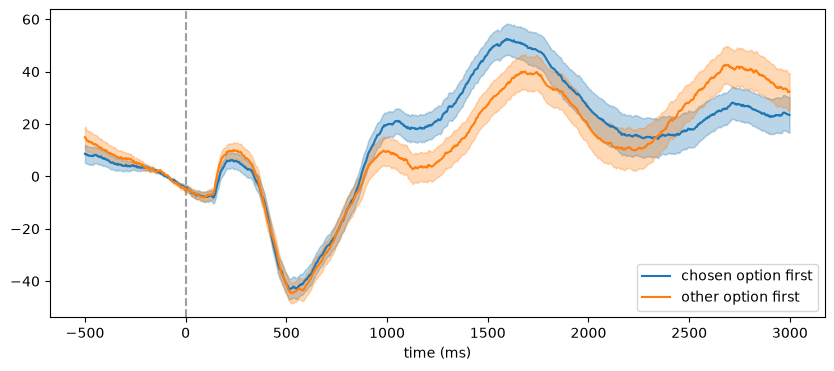

In [12]:
chosen_first = first["left_chosen"].values < np.nan_to_num(first_other, nan=np.inf)

erpd = seg.pupil.baseline_correct((-200, 0), eyes="left", inplace=False)
fig, ax = plt.subplots(figsize=(10, 4))
erpd.keep(chosen_first).pupil.plot("left", ax=ax, label="chosen option first")
erpd.keep(~chosen_first).pupil.plot("left", ax=ax, label="other option first",
                                    show_legend=True);

## Several participants

`pp.group_segments()` averages the trials of each participant (a list of
segments, or a dict with their names). The result is again a
`SegmentedEyeData` object, with one column per participant, so the fixation
curves and ERPDs of the group are means across participants. Here, the
first and second half of the session stand in for two participants:

SegmentedEyeData(group_stimulus): 2 averages (of 299 trials) x 1750 time points (-500 to 2998 ms, 500 Hz)
  channels: left_chosen (7.0% missing), left_other (7.0% missing)
  epochs: Epochs 'S_' | 2 epochs without time, window (-500, 3000) ms
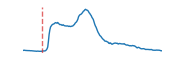
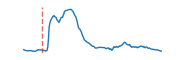

In [13]:
first_half = seg.filter(trial=lambda t: t <= 150)
second_half = seg.filter(trial=lambda t: t > 150)
group = pp.group_segments({"first half": first_half, "second half": second_half},
                          channels=["left_chosen", "left_other"])
group

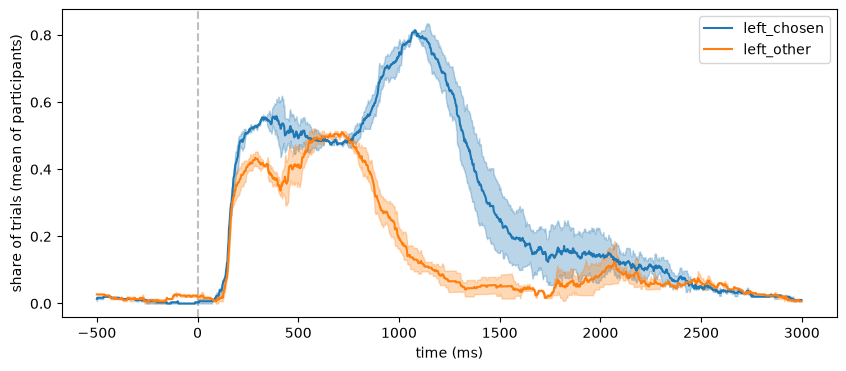

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
group.plot(["left_chosen", "left_other"], ax=ax, show_legend=True)
ax.set_ylabel("share of trials (mean of participants)");

The participants are columns like the trials before, with their name and
number of trials in the metadata of the epochs. Averages by other metadata
work the same way: `pp.concat_segments()` stacks the trials of all
participants (with the metadata column `"subject"`), and `average(by=...)`
averages them, e.g., per participant and side of the chosen option:

In [15]:
both = pp.concat_segments({"first half": first_half, "second half": second_half},
                          channels=["left_chosen", "left_other"])
means = both.average(by=["subject", "side"])
means.epochs.as_pandas()[["label", "subject", "side", "n_trials"]]

,label,subject,side,n_trials
0,first half/2.0,first half,2.0,88
1,first half/1.0,first half,1.0,61
2,second half/1.0,second half,1.0,88
3,second half/2.0,second half,2.0,62


The segments, with their ROI channels, can be saved with
`seg.write_file("stimulus.h5")` and loaded with
`pp.SegmentedEyeData.from_file()`.